# MNIST Digit Classification from scratch

MNIST is a dataset of images of single digits. 

Here, you will find the code for digit classification of the MNIST dataset (digits 1-9) **from scratch**.

<br>My goal is to investigate the differences and similarity between **multilayer perceptons (a type of artificial neural network) are to the human brain (biological neural networks)**.

*NN: neural network*

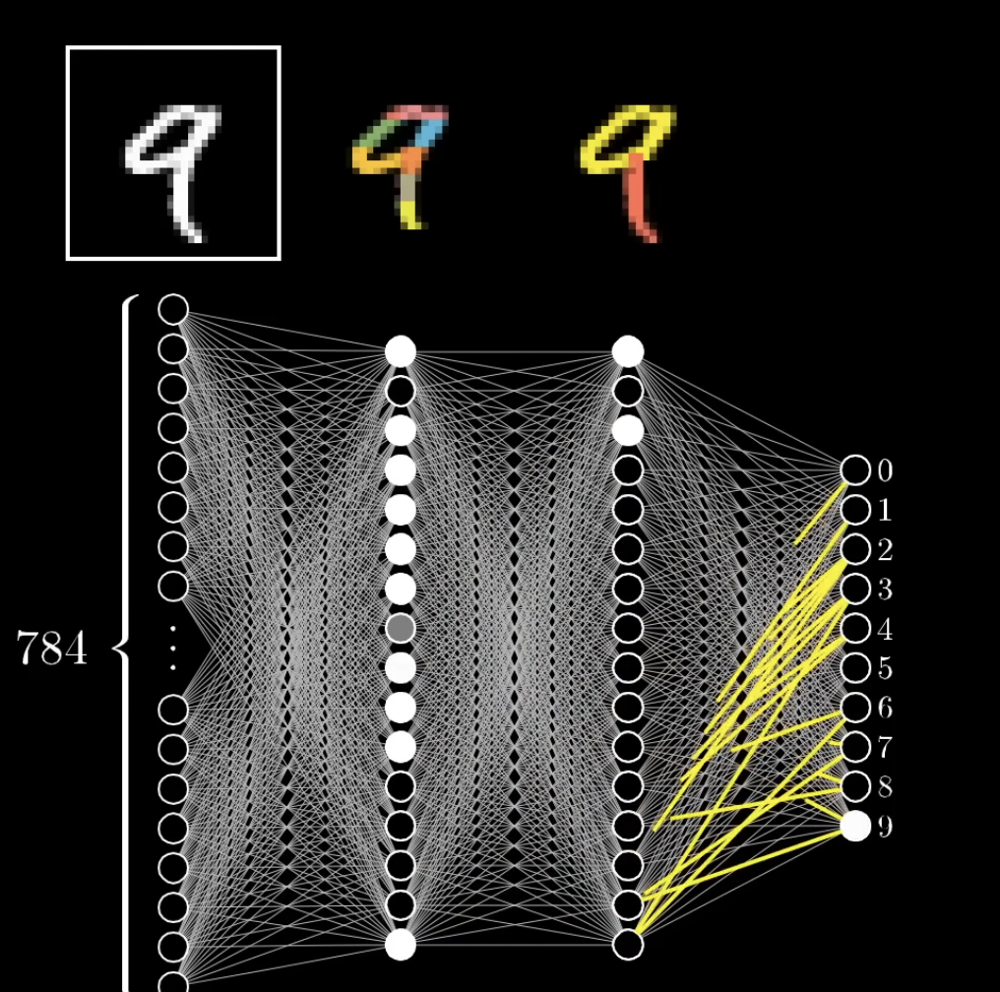

In [33]:
from IPython.display import Image, display
display(Image(filename='../assets/Neural-Networks/1-NN.png', width=300, height=300))

### Architecture

tldr: 
- input: 784 numbers (pixels)
- output 10 numbers
- parameters: 13,002 weights/biases
<br>--------
- input layer: 784 neurons (since 784 pixels per image)
    - each neuron holds one pixel of an image
        - its activation value (the number the neuron holds) is the brightness of the pixel (between 0-1, 0 for pure black & 1 for white)
- 2 hidden layers
    - hopefully (since somewhat arbitrary choice):*
    - first layer: corresponds to "little edges" in the images*
    - second layer: corresponds to patterns from the edges (from the first layer) ex. a loop, a line, etc*
- output layer: each neuron represents the possible output values 0-9. the brightest neuron in the last layer represents the digit that the image shows, i.e. the neural network's final output
<br>--------
- Every progressive layer in the network corresponds to increasingly larger and larger edges. Etc. The second layer corresponds to small edges, and the next layer corresponds to overall patterns (ex. a loop) from those small edges
    - pixels -> edges -> patterns -> digits

<br>
-->*note: the NN doesn't actually do this. the network just wants to minimize the cost function, and it may hold weights that accurately classify the digits, but do not capture any patterns

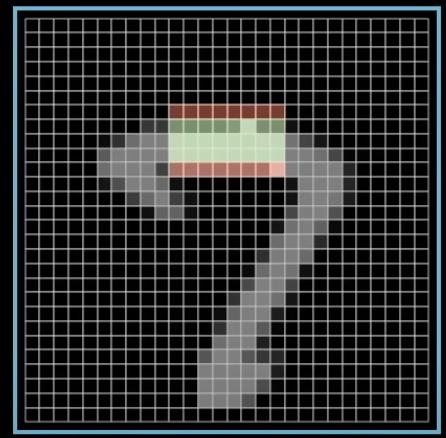

In [ ]:
display(Image(filename='../assets/Neural-Networks/3-weights.png', width=300, height=300))

### The Math!
- Activations need to be between 0 - 1, so use **ReLu**

The activation of the neuron (in image below) is a measure of how **positive** the relevant **weighted sum (w1a1 + w2a2 + w3a3 + ... + wnan)** is. 

But it may not always be the case that you want a neuron to be inactive if the weighted sum is less than zero. For example, if you want a neuron to be active if the weighted sum is greater than 10, you can simply add a bias of 10 to the weighted sum. **weighted sum: (w1a1 + w2a2 + w3a3 + ... + wnan + bias)**

in other words:
- **weights: tell you what pixel pattern this neuron in the second layer is picking up on** (see image below)
- **bias: determines how high the weighted sum needs to be before the neuron starts getting meaningfully active.**

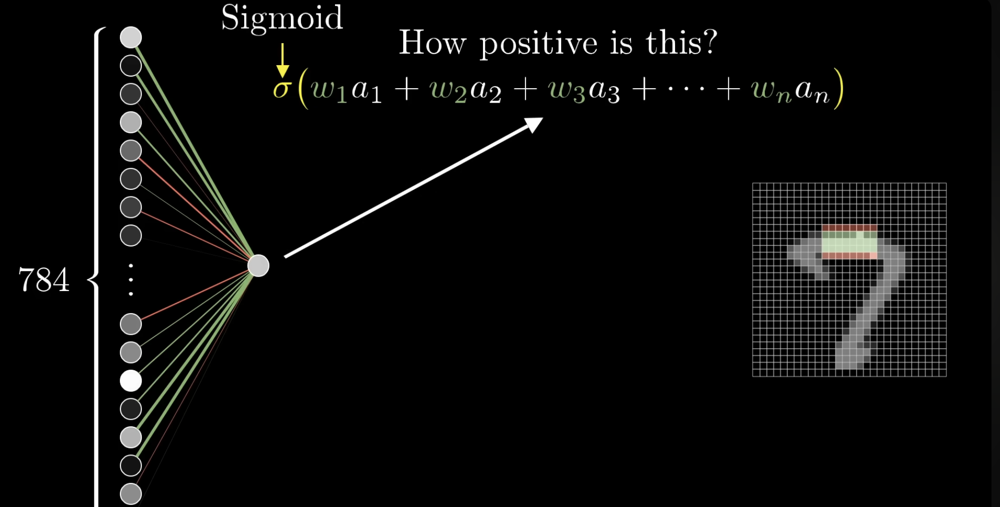

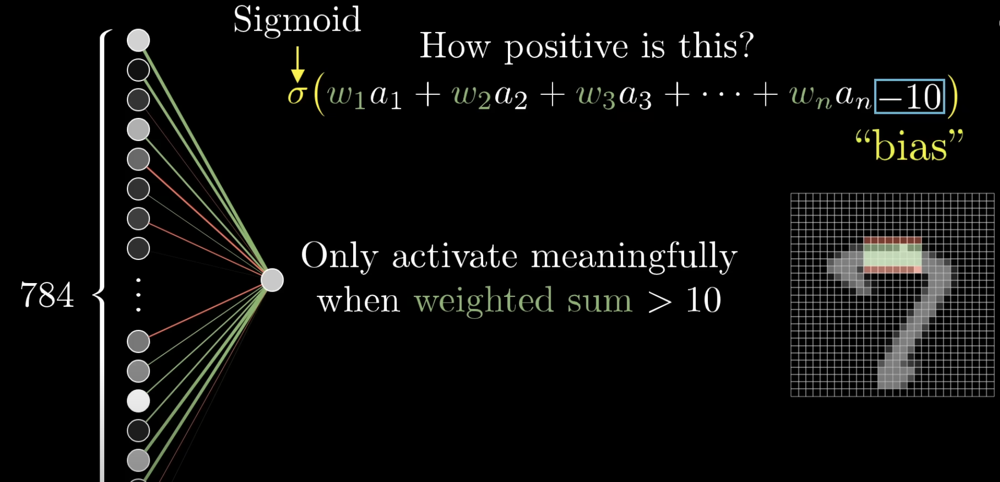

In [ ]:
display(Image(filename='../assets/Neural-Networks/4-weightedSum.png', width=400, height=400))
display(Image(filename='../assets/Neural-Networks/5-weightsAndBias.png', width=400, height=400))

## Structure of a Neural Network in code:

### Neuron

In [ ]:
import numpy as np

class Neuron:
    def __init__(self, num_inputs):     # num_inputs: how many inputs neural network should take
        self.weights = np.random.rand(num_inputs) * 0.01     # random initially
        self.bias = 0                                        # random initially

    def relu(self, x):
        return np.maximum(0, x)
    
    def forward(self, activations):
        weighted_sum = np.dot(self.weights, activations)
        activation_function = self.relu(weighted_sum + self.bias)
        return activation_function

### Layer

In [ ]:
class Layer:
    def __init__(self, num_neurons, num_inputs_per_neuron):
        self.neurons = [Neuron(num_inputs_per_neuron) for _ in range(num_neurons)]

    def forward(self, activations):
        return np.array([neuron.forward(activations) for neuron in self.neurons])
    

### Neural Network

In [ ]:
class NeuralNetwork:
    def __init__(self, layer_sizes):
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(Layer(layer_sizes[i+1], layer_sizes[i]))

    def forward(self, activations):
        for layer in self.layers:
            activations = layer.forward(activations)
        return activations

The math in matrix format:

*note: these images show sigmoid, but ReLu is generally used instead*

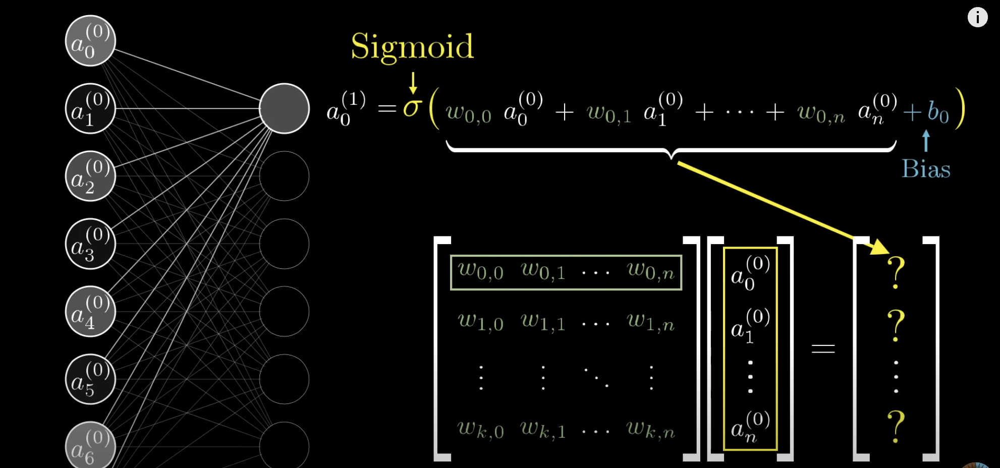

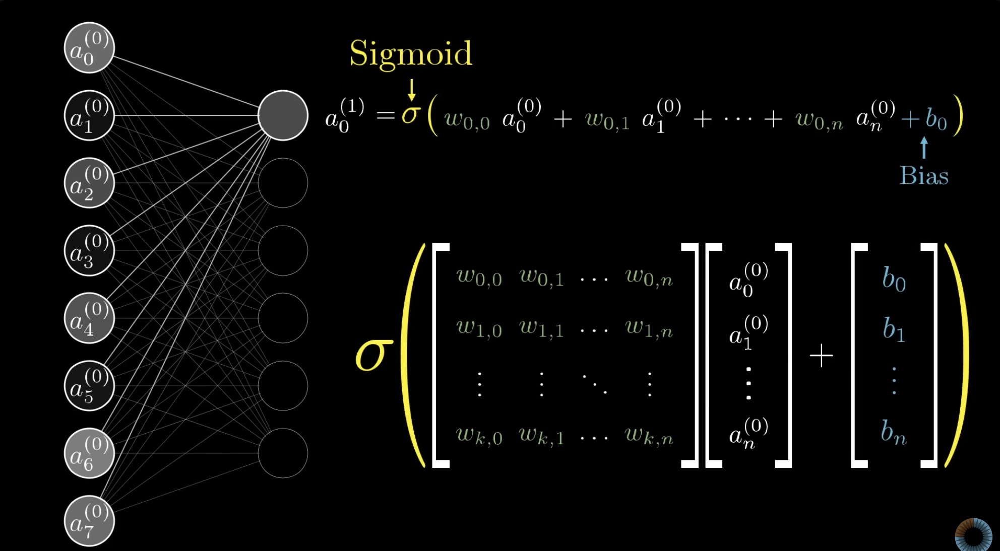

In [ ]:
display(Image(filename='../assets/Neural-Networks/6-matrices1.png', width=500, height=500))
display(Image(filename='../assets/Neural-Networks/7-matrices2.png', width=500, height=500))

### Cost Function

initially, weights and biases are initialized randomly (whole point of training a NN is to determine the best values for the weights and biases!). so the first run of the NN is VERY BAD/inaccurate. 
    - so you define a **cost function**!

**Cost function**: determines how well a NN performs. i.e. determines the average of the difference between the activations of the final layer of a run with the DESIRED activations of final layer of that run (true labels).

- **input of cost function: NN's output (influenced by weights and biases) of a run, and the run's true labels**

- the cost function is SMALL when image is classified correctly, but LARGE when NN doesn't really know what its doing
    - thus, want to **MINIMIZE cost function as much as possible (Gradient Descent!)**


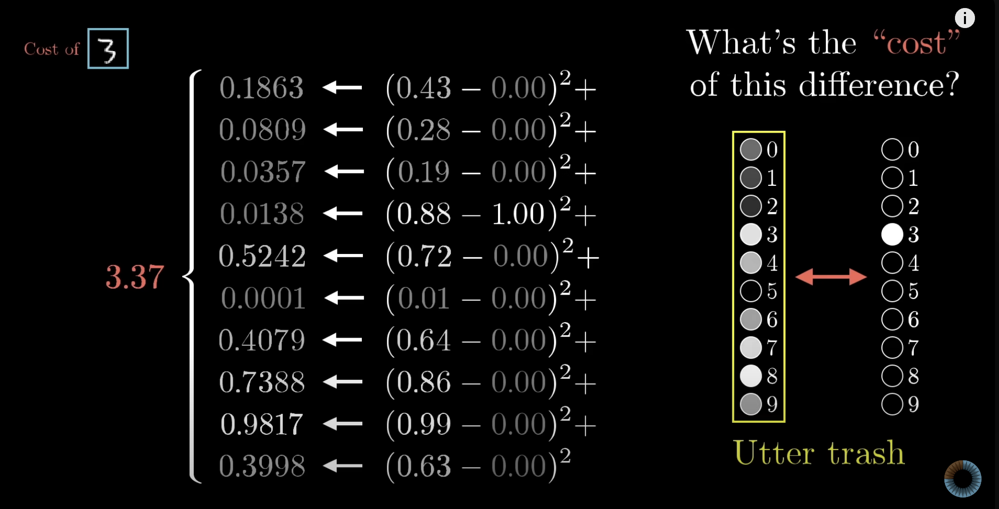

In [ ]:
display(Image(filename='../assets/Neural-Networks/8-cost.png', width=500, height=500))

### Gradient Descent

Optimization algorithm to **minimize the cost function**.
<br>Uses gradients to update/adjust weights and biases in the direction that minimizes the cost.

We look for the **negative** gradient of the cost function, which tells us how we need to change the weights and biases to most efficiently decrease the cost.

*Backpropagation is the algorithm used to CALCULATE these gradients*

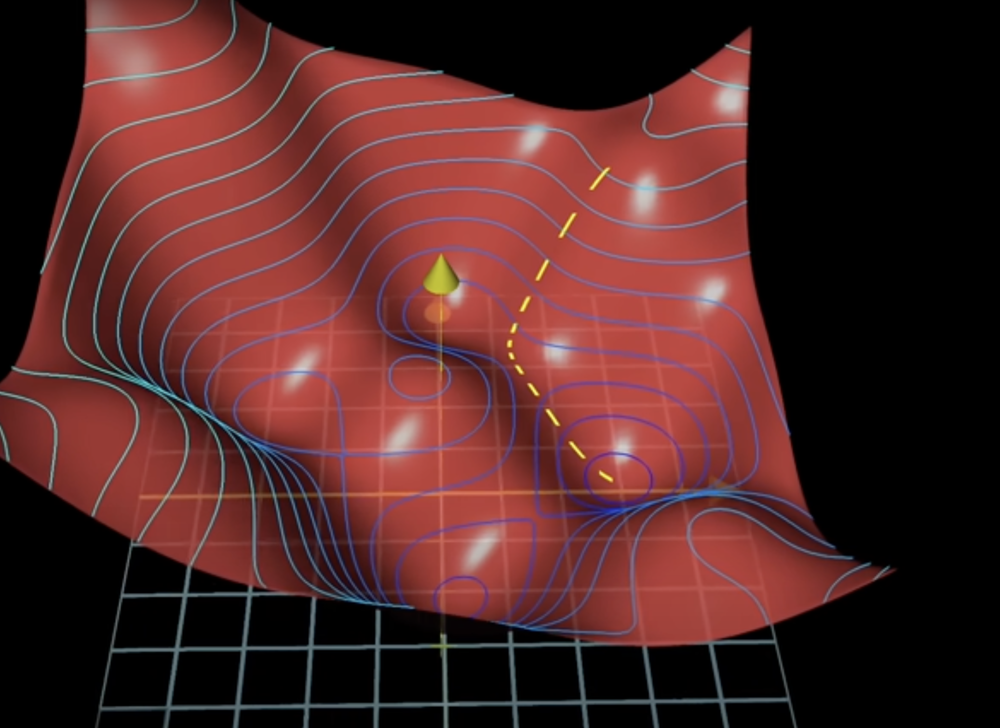

In [ ]:
display(Image(filename='../assets/Neural-Networks/9-gradientDescent.png', width=500, height=500))

### Backpropagation

The algorithm for determining **how a SINGLE training example would like to nudge the weights and biases, not just if they should go up or down, but in terms of what relative proportions to those changes cause the most rapid decrease to the cost.**

The magnitude of a gradient is how sensitive the cost function is to each weight and bias.
<br><br>
Ex. you have gradients [3.2, 0.1]. Nudging the weight with gradient 3.2 results in a cost 32x greater, than the cost when nudging (the same way) the weight with gradient 0.1
<br><br>
Activation is influenced in three ways:
- Changing the bias
<br>
- Increasing a weight, in proportion to its activation (the larger the activation, the greater the change)
<br>
- Changing all activations in previous layer, in proportion to its weights (the larger the weight, the greater the change) (but don't have direct influence over activations themselves, just weights and biases)

"Propagate backwards": backpropagation is applied in the direction from the last layer to the first layer.
<br><br>------
<br>

**∂C/∂w = ∂C/∂a × ∂a/∂z × ∂z/∂w**

*where C is cost, w is weight, a is activation (output of neuron), z is the weighted sum (input to neuron, before activation).*

This tells us how much the cost (error) would change if we slightly adjusted a particular weight. 
- It indicates the direction to change the weight. If the derivative is positive, decreasing the weight will reduce the error, and vice versa.
- The magnitude tells us how sensitive the error is to changes in this weight. Larger magnitude = weight has bigger impact on error



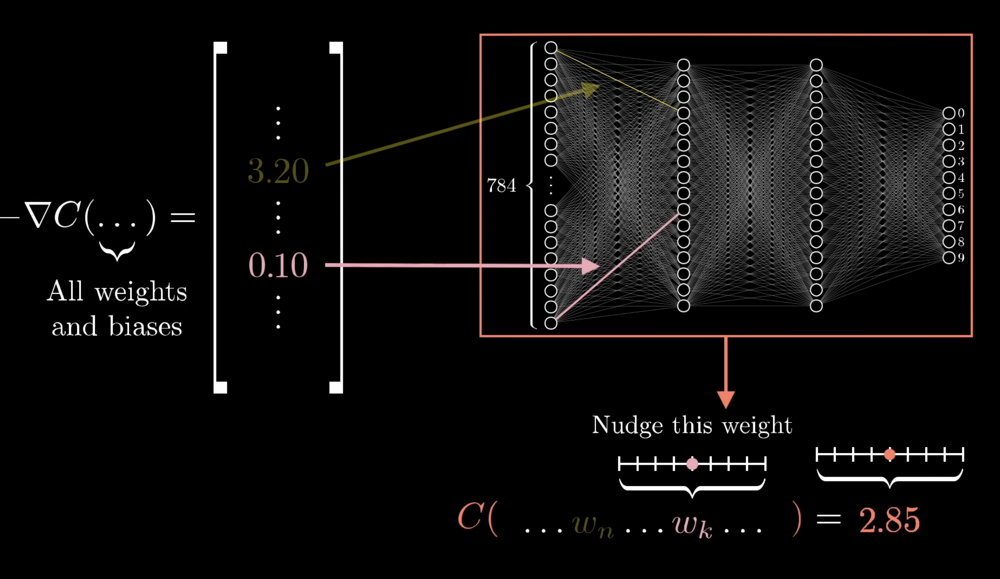

In [ ]:
display(Image(filename='../assets/Neural-Networks/10-backprop.png', width=500, height=500))

Averaged nudges to each weight and bias is the negative gradient of the cost function.

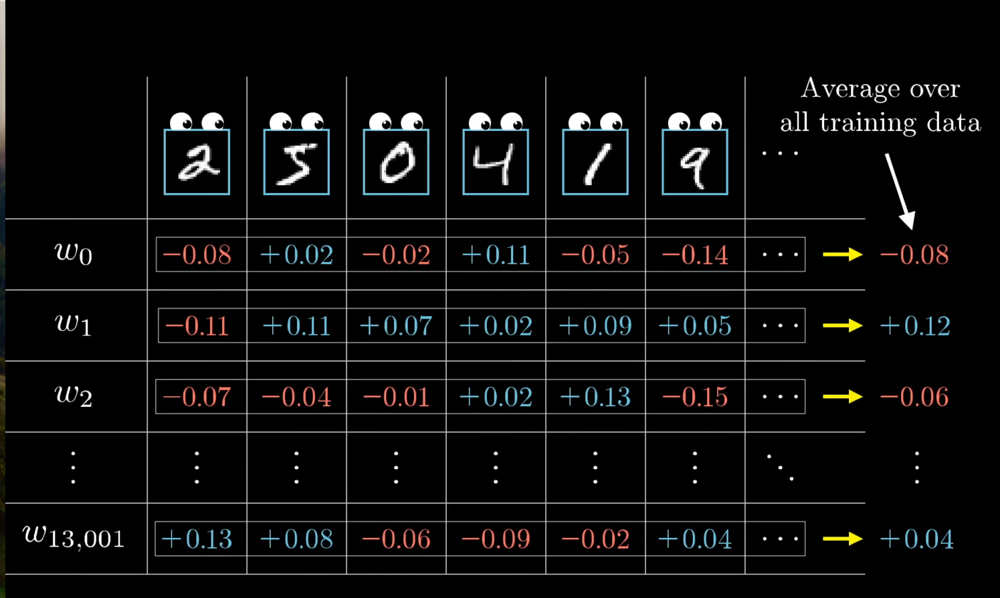

In [ ]:
display(Image(filename='../assets/Neural-Networks/11-backprop-2.png', width=500, height=500))

## Code for MNIST (from scratch)!

### Key Notes

- initially, weights and biases are initialized randomly (whole point of training is to determine the best values for the weights and biases!)

### The Neuron class:

- Implements forward pass with ReLU activation
- Implements backward pass, applying the chain rule
- Updates weights and bias based on the calculated gradients


### The Layer class:

- Manages a collection of neurons
- Implements forward and backward passes for the entire layer


### The NeuralNetwork class:

- Manages multiple layers
- Implements forward pass through all layers
- Implements the training loop, including:

    - Forward pass
    - Loss calculation
    - Backward pass (backpropagation)
    - Updating of all weights and biases

Data for the neural network is found here: 
https://www.kaggle.com/datasets/hojjatk/mnist-dataset

In [ ]:
import numpy as np
import struct
import os
class Neuron:
    def __init__(self, num_inputs):
        self.weights = np.random.randn(num_inputs, 1) * 0.01
        self.bias = np.zeros((1, 1))
        self.last_input = None
        self.last_output = None

    def relu(self, z):
        return np.maximum(0, z)
    
    def relu_derivative(self, z):
        return np.where(z > 0, 1, 0)
    
    def forward(self, activations):
        self.last_input = activations
        z = np.dot(activations, self.weights) + self.bias
        self.last_output = self.relu(z)
        return self.last_output

    def backward(self, dC_da, learning_rate):
        da_dz = self.relu_derivative(self.last_output)
        dC_dz = dC_da * da_dz
        dC_dw = np.dot(self.last_input.T, dC_dz)
        dC_db = np.sum(dC_dz, axis=0, keepdims=True)

        self.weights -= learning_rate * dC_dw
        self.bias -= learning_rate * dC_db

        return np.dot(dC_dz, self.weights.T)


    # output_gradient: 
        # A positive gradient means we need to decrease that output
        # A negative gradient means we need to increase that output

    # learning_rate: how big of a step is taken while updating weights and biases


class Layer:
    def __init__(self, num_neurons, num_inputs_per_neuron):
        self.neurons = [Neuron(num_inputs_per_neuron) for _ in range(num_neurons)]

    def forward(self, activations):
        return np.hstack([neuron.forward(activations) for neuron in self.neurons])
    
    def backward(self, output_gradient, learning_rate):
        return np.sum([neuron.backward(output_gradient[:, [i]], learning_rate) for i, neuron in enumerate(self.neurons)], axis=0)

class NeuralNetwork:
    def __init__(self, layer_sizes):
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(Layer(layer_sizes[i+1], layer_sizes[i]))

    def forward(self, activations):
        for layer in self.layers:
            activations = layer.forward(activations)
        return activations
    
    def mse_loss(self, y, activations):    
        return np.mean((activations-y)**2)
    
    def derivative_mse_loss(self, y, activations):
        return 2*(activations-y) / y.shape[0]
    
    def train(self, X, y, epochs, learning_rate, batch_size=32):
        for epoch in range(epochs):
            total_loss = 0
            for i in range(0, len(X), batch_size):
                X_batch = X[i:i+batch_size]
                y_batch = y[i:i+batch_size]
                
                outputs = self.forward(X_batch)
                loss = self.mse_loss(y_batch, outputs)
                total_loss += loss * len(X_batch)

                output_gradient = self.derivative_mse_loss(y_batch, outputs)
                for layer in reversed(self.layers):
                    output_gradient = layer.backward(output_gradient, learning_rate)

            avg_loss = total_loss / len(X)
            print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss}")

    def predict(self, X):
        return self.forward(X)

In [ ]:
# DATA

# load and preprocess the data

def load_mnist(path, kind='train'):
    """Load MNIST data from `path`"""
    labels_path = os.path.join(path, f'{kind}-labels.idx1-ubyte')
    images_path = os.path.join(path, f'{kind}-images.idx3-ubyte')
    
    with open(labels_path, 'rb') as lbpath:
        magic, n = struct.unpack('>II', lbpath.read(8))
        labels = np.fromfile(lbpath, dtype=np.uint8)

    with open(images_path, 'rb') as imgpath:
        magic, num, rows, cols = struct.unpack('>IIII', imgpath.read(16))
        images = np.fromfile(imgpath, dtype=np.uint8).reshape(len(labels), 784)

    return images, labels

# x: images
# y: labels/correct answers
X_train, y_train = load_mnist('../data/MNIST')
X_test, y_test = load_mnist('../data/MNIST', kind='t10k')

# normalize the data
    # scale all pixel values from 0-255 to 0-1
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# one-hot encode the labels
    # represent categorical data as binary vectors
y_train_onehot = np.eye(10)[y_train]
y_test_onehot = np.eye(10)[y_test]


# create and train the network
nn = NeuralNetwork([784, 128, 64, 10])
nn.train(X_train, y_train_onehot, epochs=10, learning_rate=0.01, batch_size=32)

# eval the network
predictions = nn.predict(X_test)
accuracy = np.mean(np.argmax(predictions, axis=1) == y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

FileNotFoundError: [Errno 2] No such file or directory: '../data/MNIST/train-labels.idx1-ubyte'

## Same Neural Network, using PyTorch

In [ ]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# check available device
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using mps device


Define the Neural Network

Non-linear activations (in this case, ReLu) are what create the complex mappings between the model’s inputs and outputs. They are applied after linear transformations to introduce nonlinearity, helping neural networks learn a wide variety of phenomena.

In [ ]:
class NeuralNetwork(nn.Module):                      # nn.Module: a base class with functions for neural networks
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()                 # flatten input

        self.linear_relu_stack = nn.Sequential(     # nn.Sequential: automates the forward pass of layers it contains
            nn.Linear(28*28, 128),                  # nn.Linear: matrix multiplication and bias addition (calculates weighted sum)
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)          # logits: raw, unnormalized predictions generated by the NN
        return logits
    
    # note: we don't call model.forward() directly. PyTorch handles this automatically when we call 
    # the model as a function

Create an instance of the Neural Network, move it to device, & print its structure

In [ ]:
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


Prepare input data, pass data through the model, apply softmax to probabilities and find the class with the highest probability.

SoftMax: The last linear layer of the neural network returns logits - raw values in [-infty, infty] - which are passed to the nn.Softmax module. The logits are scaled to values [0, 1] representing the model’s predicted probabilities for each class. dim parameter indicates the dimension along which the values must sum to 1.

In [ ]:
X = torch.rand(1, 28, 28, device=device)        # random tensor X, represents a single 28x28 iamge
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)        # converts a vector into a probability distribution (probability distribution: sum of all numbers is 1)
                                               # (converts raw output values to 0 and 1 while maintaining rank of largest/smallest values)
                                               # sum of all values of raw output after softmax = 1

y_pred = pred_probab.argmax(1)                 # argmax: converts highest raw output to 1, and rest of raw output to 0
print(f"Predicted class: {y_pred}")

Predicted class: tensor([8], device='mps:0')


Model Layers

In [ ]:
input_image = torch.rand(3,28,28)           # 3 random assets
print(input_image.size())

torch.Size([3, 28, 28])


In [ ]:
# initialze the nn.Flatten layer to convert each 2D 28x28 image into an array of 784 pixels (minibatch dimension of dim=0 is maintained)

flatten = nn.Flatten()
flat_image = flatten(input_image)
print(flat_image.size())

torch.Size([3, 784])


In [ ]:
# nn.Linear: module that applies a linear transformation on the input, using its stored weights and biases

layer1 = nn.Linear(in_features=28*28, out_features=128)      # calculate weighted sum
                                      # out_features: number of neurons in the output of this linear layer
hidden1 = layer1(flat_image)
print(hidden1.size())

torch.Size([3, 128])


In [ ]:
print(f"Before ReLU: {hidden1}\n\n")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU: {hidden1}")

Before ReLU: tensor([[-8.3385e-03, -4.9517e-02, -1.8320e-01,  2.1403e-01, -9.4481e-02,
         -3.6384e-01,  1.3191e-01, -2.0709e-01, -2.2902e-02, -2.3409e-01,
          3.4571e-01, -1.3503e-01, -4.3993e-01, -1.6247e-01,  3.2610e-01,
          4.7959e-01, -2.2942e-01,  2.7590e-01, -4.1877e-02, -1.0733e-01,
         -2.8198e-01, -2.5267e-01,  8.2417e-03, -3.0443e-01, -4.4964e-02,
         -1.9870e-01,  2.5819e-01,  5.3739e-02,  1.2640e-01, -2.5732e-03,
          2.7279e-02, -4.7998e-01, -4.7761e-01, -1.2692e-01,  2.8220e-02,
          1.2308e-01, -5.4463e-01,  1.8690e-01,  1.0581e-01,  6.8954e-03,
          1.4914e-01,  2.0232e-01,  4.5167e-01, -3.0118e-01, -5.2835e-02,
          3.7388e-01, -2.2155e-01, -1.3969e-01,  4.9207e-01,  2.7891e-01,
         -4.5720e-01, -7.7432e-02, -6.0746e-02, -2.0967e-01,  8.2033e-01,
          1.2078e-01,  1.7724e-01, -3.7668e-01,  5.1052e-02,  2.5480e-01,
         -6.0284e-02,  1.6293e-01,  7.9740e-02,  7.5648e-01,  3.4414e-01,
          3.6700e-01, -1.

In [ ]:
print(f"Model structure: {model}\n\n")

for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


Layer: linear_relu_stack.0.weight | Size: torch.Size([128, 784]) | Values : tensor([[-0.0323, -0.0218, -0.0250,  ...,  0.0347, -0.0264, -0.0257],
        [-0.0027, -0.0010,  0.0261,  ...,  0.0158, -0.0013,  0.0239]],
       device='mps:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.0.bias | Size: torch.Size([128]) | Values : tensor([ 0.0044, -0.0189], device='mps:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.weight | Size: torch.Size([64, 128]) | Values : tensor([[-8.0585e-02,  8.0916e-02,  3.7520e-02, -4.3591e-02, -4.3593e-02,
         -3.8098e-02, -7.5200e-02,  3.5062e-02,  3.8367e-03,  7.6364e-02,
          4.4087e-02, -6.6770e-02


*Credit to 3Blue1Brown for the visuals!*